# Lab 16.3: Find and Knock Out Induction Heads

Run-only notebook for Chapter 16, with one optional edit at the end. GPT-2 small reads 50 random tokens and then the same 50 again. On the repeated copy, a model with induction heads can predict each token by looking back.

In [1]:
import os, random, time
import numpy as np, torch, matplotlib
import matplotlib.pyplot as plt
from transformer_lens import HookedTransformer
torch.set_grad_enabled(False)
torch.manual_seed(0)
from importlib.metadata import version
print("torch", torch.__version__, "| transformer-lens", version("transformer-lens"), "| numpy", np.__version__)
t0 = time.time()
model = HookedTransformer.from_pretrained("gpt2", device="cpu")   # GPT-2 small, 124M parameters
print(f"loaded in {time.time() - t0:.0f} s")

torch 2.6.0 | transformer-lens 2.18.0 | numpy 1.26.4


Loaded pretrained model gpt2 into HookedTransformer
loaded in 1 s


In [2]:
SEQ, BATCH = 50, 8                     # optional edit: try SEQ = 20 or 100
rand = torch.randint(1000, 20000, (BATCH, SEQ))
tokens = torch.cat([torch.full((BATCH, 1), model.tokenizer.bos_token_id), rand, rand], dim=1)
logits, cache = model.run_with_cache(tokens, names_filter=lambda n: n.endswith("pattern"))

def loss_per_position(logits):
    logp = logits.log_softmax(-1)[:, :-1]
    return -logp.gather(-1, tokens[:, 1:, None])[..., 0].mean(0).numpy()

loss = loss_per_position(logits)
print(f"mean loss, first copy {loss[:SEQ].mean():.2f} nats; repeated copy {loss[SEQ:].mean():.2f} nats")

mean loss, first copy 12.36 nats; repeated copy 0.41 nats


**Checkpoint 1:** about 12.4 nats on the first copy, about 0.41 on the repeated copy.

## Score every head

The induction score of a head is its average attention, from each token of the repeated copy, to the token right after that token's earlier occurrence. The previous-token score is its average attention to the immediately preceding position.

top induction heads:      [('5.5', 0.94), ('6.9', 0.92), ('7.10', 0.92), ('5.1', 0.91), ('7.2', 0.84), ('10.1', 0.54), ('10.7', 0.5), ('9.6', 0.5)]
top previous-token heads: [('4.11', 0.99), ('3.7', 0.54), ('6.8', 0.5), ('2.2', 0.48), ('3.2', 0.41), ('5.6', 0.41), ('2.9', 0.37), ('3.8', 0.35)]


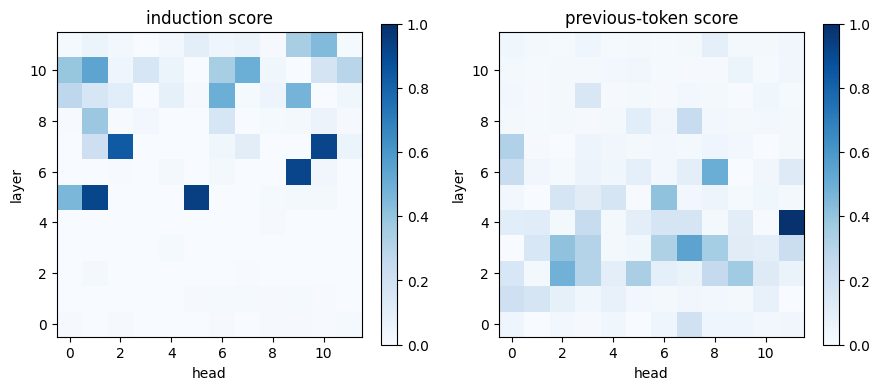

In [3]:
dest = torch.arange(SEQ + 1, 2 * SEQ + 1)
induction = np.zeros((12, 12)); previous = np.zeros((12, 12))
for layer in range(12):
    pat = cache[f"blocks.{layer}.attn.hook_pattern"]          # batch, head, destination, source
    induction[layer] = pat[:, :, dest, dest - SEQ + 1].mean((0, 2)).numpy()
    allpos = torch.arange(2, 2 * SEQ + 1)
    previous[layer] = pat[:, :, allpos, allpos - 1].mean((0, 2)).numpy()

def ranked(M, k=8):
    idx = np.argsort(-M.ravel())[:k]
    return [(f"{i // 12}.{i % 12}", round(float(M.ravel()[i]), 2)) for i in idx]
print("top induction heads:     ", ranked(induction))
print("top previous-token heads:", ranked(previous))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, M, t in zip(axes, [induction, previous], ["induction score", "previous-token score"]):
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1, origin="lower"); ax.set_title(t)
    ax.set_xlabel("head"); ax.set_ylabel("layer"); fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

**Checkpoint 2:** induction heads 5.5 (about 0.94), 6.9, 7.10, 5.1 (about 0.91 to 0.92) and 7.2 (about 0.84); the previous-token heads sit in earlier layers. An induction head needs a previous-token head before it: check that they are in earlier layers.

## Knock them out

Mean-ablate the six top induction heads (replace each head's output with its average over positions and sequences), then six control heads chosen at random from heads ranked 21st or lower.

top 6: [(5, 5), (6, 9), (7, 10), (5, 1), (7, 2), (10, 1)] -> repeated-copy loss 5.73
control: [(11, 11), (2, 11), (3, 0), (9, 5), (9, 4), (5, 6)] -> repeated-copy loss 0.43


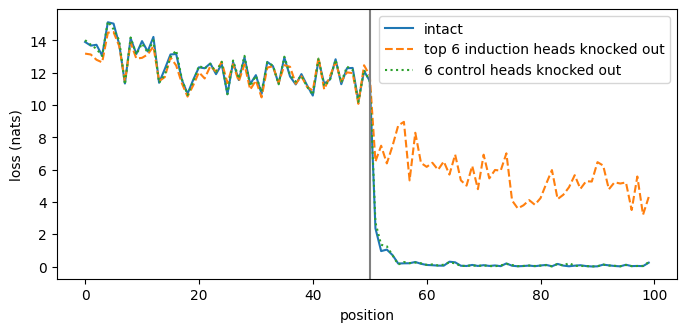

In [4]:
def ablate(heads):
    def hook(act, hook):
        layer = int(hook.name.split(".")[1])
        for l, h in heads:
            if l == layer:
                act[:, :, h] = act[:, :, h].mean((0, 1))
        return act
    layers = sorted({l for l, _ in heads})
    return loss_per_position(model.run_with_hooks(tokens, fwd_hooks=[(f"blocks.{l}.attn.hook_z", hook) for l in layers]))

order = np.argsort(-induction.ravel())
top6 = [(i // 12, i % 12) for i in order[:6]]
control = [(i // 12, i % 12) for i in np.random.default_rng(0).choice(order[20:], 6, replace=False)]
loss_top, loss_ctrl = ablate(top6), ablate(control)
print("top 6:", top6, f"-> repeated-copy loss {loss_top[SEQ:].mean():.2f}")
print("control:", control, f"-> repeated-copy loss {loss_ctrl[SEQ:].mean():.2f}")
plt.figure(figsize=(8, 3.5))
plt.plot(loss, label="intact"); plt.plot(loss_top, "--", label="top 6 induction heads knocked out")
plt.plot(loss_ctrl, ":", label="6 control heads knocked out"); plt.axvline(SEQ, color="gray")
plt.xlabel("position"); plt.ylabel("loss (nats)"); plt.legend(); plt.show()

**Checkpoint 3:** the repeated-copy loss rises from about 0.41 to about 5.7 with the top six knocked out, and stays about 0.43 with the control heads.

## Questions

1. The loss on the repeated copy does not return to the first-copy level after the knockout. Give two reasons why.
2. What does this experiment show about induction heads, and what does it not show about in-context learning on natural text?
3. Optional edit: change `SEQ` to 20 and to 100 and rerun. Do the same heads come out on top?